In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
housing = fetch_california_housing(as_frame=True)

Просто импортим датасет и кидаем его в переменную

In [2]:
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Короче сам housing это коробка с разными вещами, потом узнаю что там лежит кроме .frame но он просто является основной таблицей, с которой мы работаем, и применяем мы .head() именно к таблице

.head() показывает первые 5 строк в таблице, если надо больше в скобки писать сколько надо

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


Тут юзая .info() показывает в RangeIndex количество строк в общем, Data columns логично количество столбцов, ниже идут сами названия столбцов и количество не ну пустых, если число столбцов не ну пустых не совпадает с общим значит есть пустые а это не круто, ну и в конце показывает тип 

In [4]:
df.shape

(20640, 9)

как будто .shape просто лоховская версия .info(), но в общем юзается в коде если нам нужно взять либо число столбцов либо число строк

In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Вот это прикольная вещь, .describe() показывает как видто метрики датасета и их разные значения, полезно видеть разные аномалии и вообще полезная штука. К примеру AveOccup в 1243.(3) как мне сказал клод может быть если это район с тюрьмами/домами престарелых/общагах типа это не считается домохозяйствами и получается что в таком районе много людей и мало домов, потот это надо будет как то считать

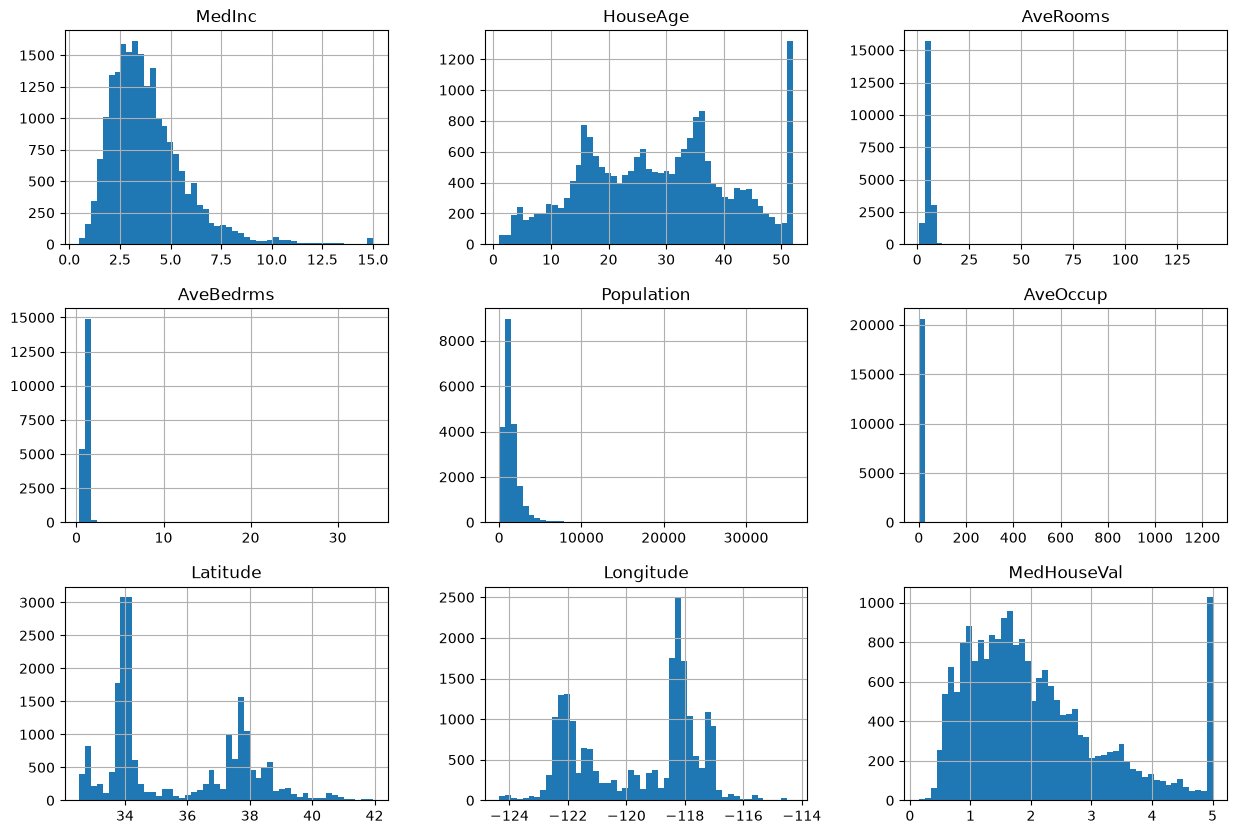

In [23]:
df.hist(figsize=(15,10), bins=50);

Нарисовались гистограммы с помощью .hist(), чтобы было понятнее добавил figsize=(a,b) размер всего что показывается и bins = a это число разбиений по иксу. Ну ещё если не поставить ; в конце то оно ещё покажет что выводит функция.

Тут ещё жоско стреляет MedHouseVal и HouseAge, ну ещё пипирка появляется на 15 у MedInc это короче произошло цензурирование, всё что >a записывается просто как а, как по мне не оч круто, надо с этим что то делать будет

Мой любимый клод сказал что их лучше не удалять потому что если модели попадётся дорогой район то ошибка будет больше, если в данных вообще не будет потолочных значений

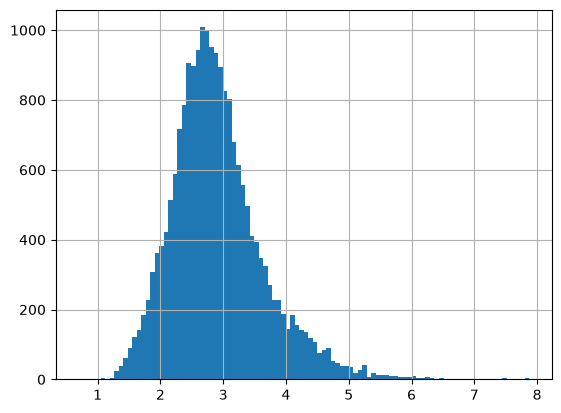

In [33]:
df.loc[(df["AveOccup"]<8), "AveOccup"].hist(bins=100);

тут я короче у df отфильтровал значение AveOccup и вывел для него отдельно гистограмму. На ней видно что больше всего в доме живёт чуть больше 2.5 людей

In [30]:
df[df["AveOccup"]<8].shape

(20587, 9)

Тут после того как ограничили стало видно что пропало 53 что примерно 0.26 процентов, то есть похуй+поебать

In [39]:
med_house_val_corr = df.corr()
med_house_val_corr["MedHouseVal"].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

Тут короче показывается корреляция признака MedHouseVal от других признаков, логично чем число больше тем кореляция больше, но это не всегда значит что низкая корелляция значит ваще не влияет. На этом примере координаты вроде не влияют почти но по факту оч сильно, зависит от географических приколов местности

<Axes: xlabel='MedInc', ylabel='MedHouseVal'>

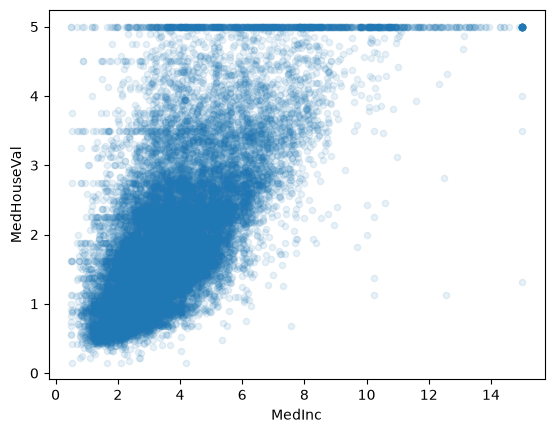

In [42]:
df.plot.scatter(x="MedInc", y = "MedHouseVal", alpha = 0.1)

Вот тут по факту строиться просто график через plot.scatter(x=, y=) где икс и игрик это метрики которые у нас есть, прикольная тоже штука, тут видно как почти линейно зависит доход от цены дома.
Параметр alpha делает точки прозрачнее